# 07 · Validación cruzada: baseline y tres variantes

Reproduce y analiza la sección 8 del informe parcial. Protocolo: 5 pliegues estratificados (etiqueta + variedad, semilla 0) solo sobre train; dev se mide una sola vez. Modelos: **M0** baseline (TF-IDF de palabras), **M1** palabras + léxico ampliado, **M2** caracteres + léxico ampliado (elegido, se optimiza) y **M3** palabras + caracteres + 24 variables + léxico ampliado. V1 (24 variables), V2 (regla de léxico mínimo) y V3 (léxico ampliado solo) son referencias simples, no variantes. El léxico ampliado está en `scripts/features/lexico_es.py` (8 rasgos con alcance de negación, lemas de spaCy).

Para recalcular todo: `python scripts/experimento/validacion_cruzada.py` (requiere spaCy y `es_core_news_md`; unos 15 minutos en CPU). Las variantes por hipótesis (sin artículos, sin puntuación, solo palabras de contenido) salen de `scripts/experimento/hipotesis_texto.py`. Este cuaderno lee las tablas ya generadas en `docs/validacion/tablas`.

In [1]:
import pandas as pd, pathlib, glob
from IPython.display import Image, display
pd.options.display.float_format='{:.4f}'.format
pd.options.display.width=200
T=pathlib.Path('../docs/validacion/tablas'); F=pathlib.Path('../docs/validacion')
print(sorted(p.name for p in T.glob('*.csv')))

['ablaciones_cv.csv', 'curva_aprendizaje.csv', 'cv_diferencias_contra_baseline.csv', 'cv_matriz_confusion_elegido.csv', 'cv_por_fold_baseline_variantes.csv', 'cv_por_variedad_oof.csv', 'dev_diferencias.csv', 'dev_f1_por_clase.csv', 'dev_resultados.csv', 'exploracion_alternativas_cv.csv', 'optimizacion_busqueda_cv.csv', 'optimizacion_efecto_marginal.csv', 'optimizacion_etapa2.csv', 'optimizacion_resultado_cv.csv', 'particiones.csv', 'registro_corridas.csv', 'variantes_hipotesis_cv.csv']


## 1. Macro-F1 por pliegue

,modelo,descripcion,fold1,fold2,fold3,fold4,fold5,media,desv,accuracy_media,f1_NEG,f1_NEU,f1_POS,macro_f1_ajuste,brecha_ajuste_valid,seg_ajuste_por_fold,ms_por_tuit
0,M0,TF-IDF de palabras (baseline),0.5296,0.5646,0.5447,0.5839,0.5571,0.5560,0.0205,0.5610,0.6235,0.4562,0.5883,0.8971,0.3411,0.3400,0.0000
1,M1,Palabras + léxico ampliado (variante 1),0.5804,0.5877,0.5957,0.5894,0.5830,0.5872,0.0059,0.5906,0.6510,0.4787,0.6320,0.8579,0.2707,0.5400,0.0000
2,M2,Caracteres + léxico ampliado (variante 2),0.6143,0.6023,0.6025,0.6024,0.5888,0.6021,0.0091,0.6041,0.6554,0.5034,0.6473,0.8242,0.2221,1.9900,0.0010
3,M3,Palabras + caracteres + 24 variables + léxico ...,0.5926,0.6017,0.6027,0.6122,0.5961,0.6011,0.0075,0.6045,0.6620,0.4969,0.6443,0.9227,0.3216,2.8600,0.0020
4,V1,24 variables solas (referencia),0.5517,0.5635,0.5418,0.5159,0.5372,0.5420,0.0178,0.5450,0.5967,0.4502,0.5792,0.5451,0.0031,0.1100,0.0000
5,V2,Regla de léxico mínimo sin entrenamiento (refe...,0.4684,0.4663,0.4409,0.4272,0.4429,0.4491,0.0177,0.4654,0.2971,0.5013,0.5489,0.4493,0.0002,0.0000,0.0010


Modelo elegido: M2


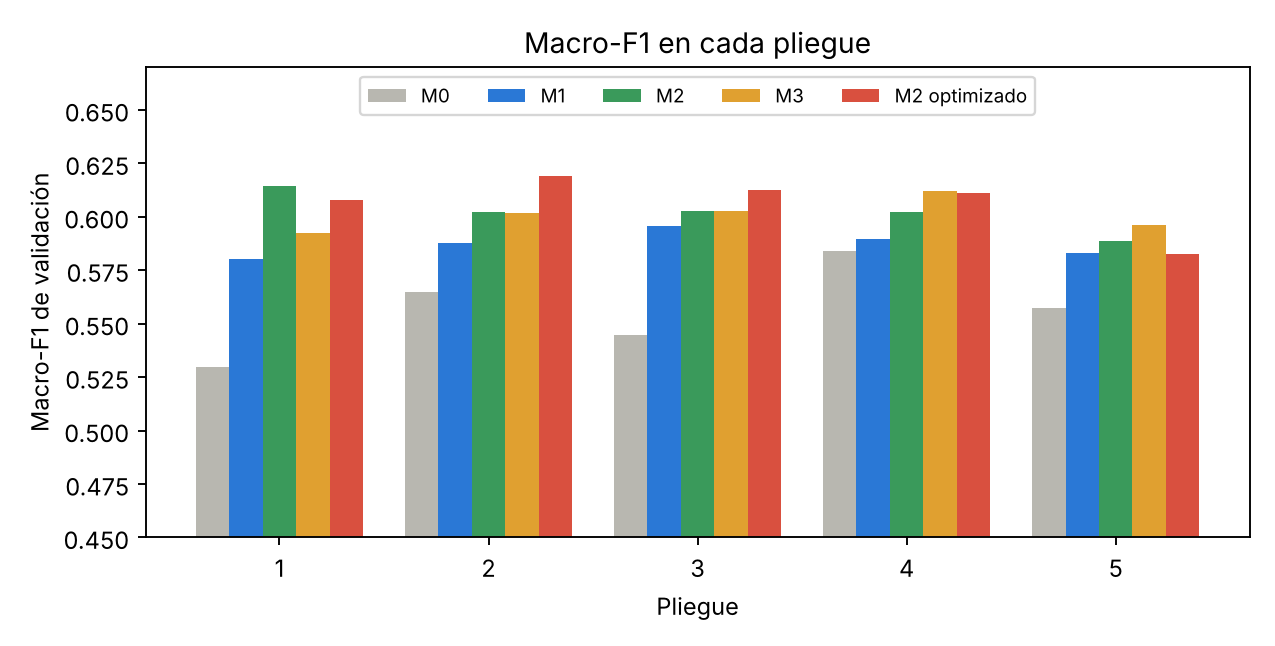

In [2]:
display(pd.read_csv(T/'cv_por_fold_baseline_variantes.csv'))
print('Modelo elegido:', (T/'modelo_elegido.txt').read_text().strip())
[display(Image(p)) for p in sorted(glob.glob(str(F/'**/fig01*.png'),recursive=True))];

## 2. Diferencias pareadas contra el baseline (bootstrap sobre predicciones fuera de muestra)

In [3]:
display(pd.read_csv(T/'cv_diferencias_contra_baseline.csv'))

,comparacion,dif_media_folds,folds_a_favor,dif_oof,ic_inf,ic_sup
0,M1 menos M0,0.0313,5,0.0315,0.0194,0.0431
1,M2 menos M0,0.0461,5,0.0461,0.0319,0.0597
2,M3 menos M0,0.0451,5,0.0452,0.0330,0.0568
3,V1 menos M0,-0.0140,1,-0.0139,-0.0297,0.0014
4,V2 menos M0,-0.1069,0,-0.1067,-0.1249,-0.0895
5,M3 menos M1,0.0138,5,0.0137,0.0035,0.0236
6,M3 menos M2,-0.0010,3,-0.0009,-0.0106,0.0089
7,M1 menos M2,-0.0148,0,-0.0146,-0.0255,-0.0029


Las tres variantes superan al baseline con IC que excluyen el cero; entre ellas no hay diferencia distinguible (M3 menos M1, M3 menos M2).

## 3. Optimización de hiperparámetros de M3

In [4]:
for n in ['optimizacion_resultado_cv','optimizacion_efecto_marginal','optimizacion_etapa2']:
    print(n); display(pd.read_csv(T/(n+'.csv')).head(20))

optimizacion_resultado_cv


,configuracion,analyzer,ngram_range,min_df,max_features,C,class_weight,fold1,fold2,fold3,fold4,fold5,media,desv,macro_f1_ajuste,dif_contra_por_defecto,ic_inf,ic_sup,folds_a_favor,seg_ajuste_por_fold
0,optimizada,char,"(2, 5)",3,60000,1.0000,balanced,0.6078,0.6189,0.6125,0.6113,0.5826,0.6066,0.0140,0.8600,0.0045,-0.0036,0.0124,3,2.6000


optimizacion_efecto_marginal


,hiperparametro,valor,mejor_macro_f1_cv
0,C,0.03,0.5608
1,C,0.1,0.5870
2,C,0.3,0.5988
3,C,1.0,0.6021
4,C,3.0,0.5911
5,C,10.0,0.5734
6,C,30.0,0.5607
7,class_weight,balanced,0.6021
8,class_weight,ninguno,0.5988
9,ngram_range,"(2, 3)",0.5988


optimizacion_etapa2


,etapa,analyzer,max_features,min_df,macro_f1_cv,desv_cv
0,2,char_wb,60000,3,0.6021,0.0091
1,2,char_wb,20000,3,0.6004,0.0101
2,2,char_wb,sin tope,3,0.6021,0.0091
3,2,char,60000,3,0.6066,0.0140
4,2,char,20000,3,0.6056,0.0117
5,2,char,sin tope,3,0.6066,0.0140
6,2,char_wb,60000,2,0.6003,0.0131
7,2,char_wb,60000,5,0.6009,0.0082


La mejor configuración de la malla es la de partida: la optimización no aporta mejora (diferencia 0,000). Es un resultado nulo y se reporta así.

## 4. Ablaciones

,componente,configuracion,control,fold1,fold2,fold3,fold4,fold5,media,desv,dif_contra_control,ic_inf,ic_sup,folds_a_favor
0,Texto de entrada,limpio,base,0.6092,0.6158,0.6042,0.6085,0.5821,0.6040,0.0129,0.0019,-0.0033,0.0073,3
1,Texto de entrada,minusculas,base,0.6143,0.6023,0.6025,0.6024,0.5888,0.6021,0.0091,0.0000,0.0000,0.0000,0
2,Texto de entrada,sin_tildes,base,0.6102,0.6175,0.6048,0.6090,0.5846,0.6052,0.0124,0.0032,-0.0020,0.0085,3
3,Texto de entrada,sin_alargamientos,base,0.6176,0.6023,0.6040,0.5982,0.5855,0.6015,0.0115,-0.0006,-0.0033,0.0024,2
4,Texto de entrada,sin_emojis,base,0.6155,0.6021,0.6049,0.6018,0.5877,0.6024,0.0099,0.0003,-0.0011,0.0019,2
5,Texto de entrada,sin_usuario_url,base,0.6228,0.5994,0.6070,0.5943,0.5814,0.6010,0.0153,-0.0011,-0.0069,0.0048,2
6,Grupo de variables (en M3),M3 sin estructural,M3 completo,0.6023,0.5976,0.6084,0.6050,0.5970,0.6021,0.0048,0.0009,-0.0033,0.0052,3
7,Grupo de variables (en M3),M3 sin expresividad,M3 completo,0.5938,0.6074,0.5990,0.6150,0.6012,0.6033,0.0082,0.0022,-0.0030,0.0075,4
8,Grupo de variables (en M3),M3 sin conversacional,M3 completo,0.5958,0.5987,0.6068,0.6171,0.5952,0.6027,0.0093,0.0017,-0.0021,0.0051,3
9,Grupo de variables (en M3),M3 sin fenomeno,M3 completo,0.6000,0.6016,0.6013,0.6039,0.5967,0.6007,0.0027,-0.0003,-0.0049,0.0040,2


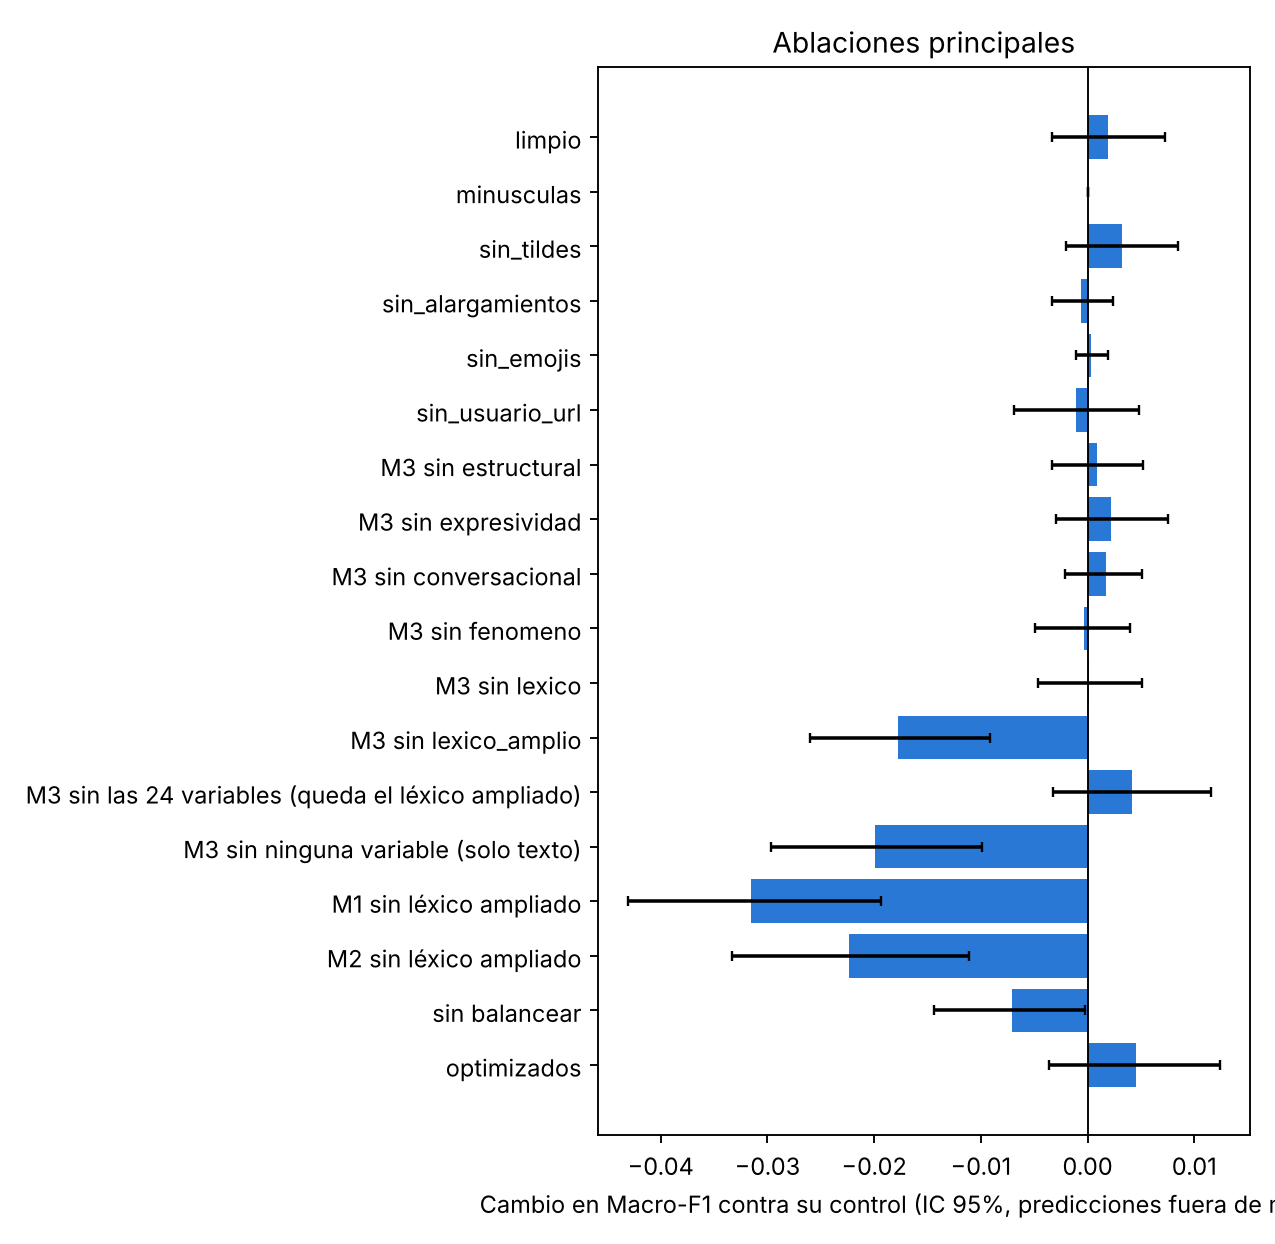

In [5]:
display(pd.read_csv(T/'ablaciones_cv.csv'))
[display(Image(p)) for p in sorted(glob.glob(str(F/'**/fig02*.png'),recursive=True))];

## 5. Variedades, matriz de confusión y curva de aprendizaje

,modelo,ambito,n,macro_f1_oof,ic_inf,ic_sup
0,M0,Todas,4802,0.5560,0.5423,0.5697
1,M0,CR,777,0.5487,0.5115,0.5840
2,M0,ES,1126,0.5377,0.5089,0.5676
3,M0,MX,990,0.5746,0.5413,0.6053
4,M0,PE,966,0.4990,0.4674,0.5309
5,M0,UY,943,0.5869,0.5555,0.6173
6,M1,Todas,4802,0.5875,0.5743,0.6011
7,M1,CR,777,0.5825,0.5461,0.6167
8,M1,ES,1126,0.5806,0.5512,0.6086
9,M1,MX,990,0.5933,0.5593,0.6241


,Unnamed: 0,pred_NEG,pred_NEU,pred_POS
0,real_NEG,1205,482,198
1,real_NEU,420,779,324
2,real_POS,167,310,917


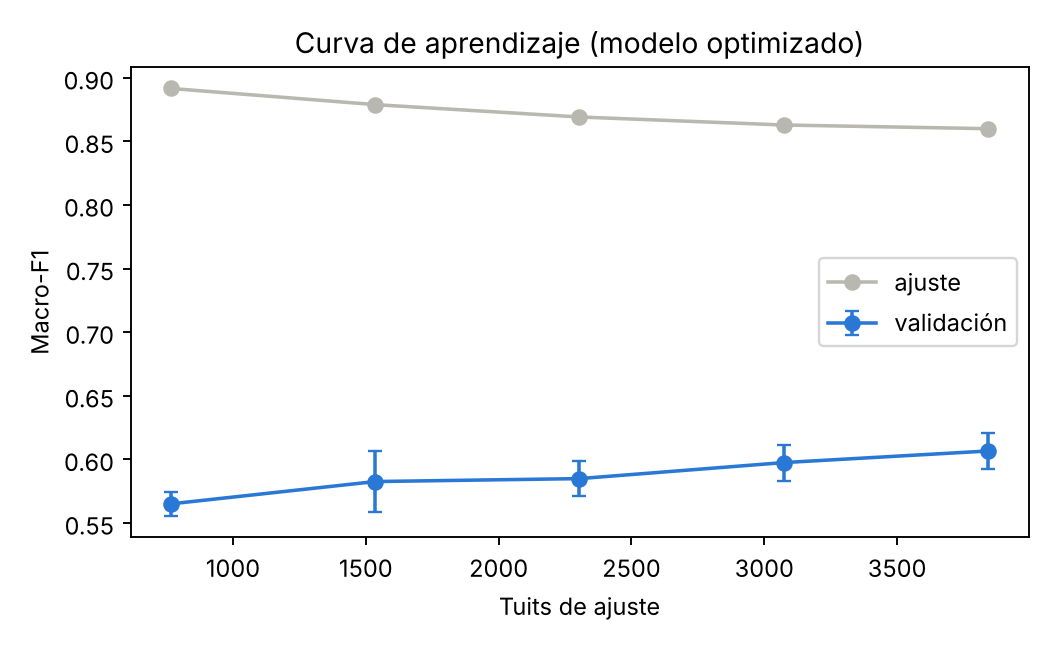

In [6]:
display(pd.read_csv(T/'cv_por_variedad_oof.csv')); display(pd.read_csv(T/'cv_matriz_confusion_elegido.csv'))
[display(Image(p)) for p in sorted(glob.glob(str(F/'**/fig03*.png'),recursive=True))];

## 6. Medición única en dev

Cada modelo se ajusta con todo train y se mide una vez en dev (2.465 tuits). Las ventajas de CV se reducen y sus IC incluyen el cero.

In [7]:
display(pd.read_csv(T/'dev_resultados.csv')); display(pd.read_csv(T/'dev_diferencias.csv')); display(pd.read_csv(T/'dev_f1_por_clase.csv'))

,modelo,ambito,n_dev,accuracy,macro_f1,ic_inf,ic_sup
0,M0 baseline,Todas,2465,0.5615,0.5556,0.5361,0.5755
1,M0 baseline,CR,390,0.5923,0.5864,0.5374,0.6340
2,M0 baseline,ES,581,0.5542,0.5382,0.4958,0.5770
3,M0 baseline,MX,510,0.5941,0.5587,0.5126,0.6028
4,M0 baseline,PE,498,0.5020,0.5010,0.4551,0.5460
5,M0 baseline,UY,486,0.5720,0.5673,0.5231,0.6101
6,M1 palabras + léxico ampliado,Todas,2465,0.5781,0.5745,0.5544,0.5937
7,M1 palabras + léxico ampliado,CR,390,0.6359,0.6320,0.5847,0.6809
8,M1 palabras + léxico ampliado,ES,581,0.5731,0.5639,0.5221,0.6042
9,M1 palabras + léxico ampliado,MX,510,0.6157,0.5835,0.5387,0.6260


,comparacion,ambito,dif,ic_inf,ic_sup,conclusion
0,M1 palabras + léxico ampliado menos M0,Todas,0.0189,0.0034,0.0341,B mejor
1,M1 palabras + léxico ampliado menos M0,CR,0.0456,0.0057,0.0846,B mejor
2,M1 palabras + léxico ampliado menos M0,ES,0.0257,-0.0062,0.0592,no se distingue
3,M1 palabras + léxico ampliado menos M0,MX,0.0248,-0.0124,0.0641,no se distingue
4,M1 palabras + léxico ampliado menos M0,PE,0.0036,-0.0299,0.0364,no se distingue
5,M1 palabras + léxico ampliado menos M0,UY,0.0006,-0.0342,0.0342,no se distingue
6,M2 caracteres + léxico ampliado menos M0,Todas,0.0207,0.0012,0.0406,B mejor
7,M2 caracteres + léxico ampliado menos M0,CR,0.0287,-0.0190,0.0754,no se distingue
8,M2 caracteres + léxico ampliado menos M0,ES,0.0080,-0.0339,0.0489,no se distingue
9,M2 caracteres + léxico ampliado menos M0,MX,0.0205,-0.0237,0.0639,no se distingue


,modelo,F1_NEG,F1_NEU,F1_POS
0,M0 baseline,0.6292,0.4514,0.5864
1,M1 palabras + léxico ampliado,0.6370,0.4747,0.6118
2,M2 caracteres + léxico ampliado,0.6418,0.4719,0.6155
3,M3 palabras + caracteres + variables + léxico,0.6558,0.4779,0.6160
4,V1 24 variables,0.5664,0.3959,0.5633
5,V2 regla de léxico,0.2970,0.4953,0.5404
6,M2 optimizado,0.6345,0.4719,0.6143
7,Salamandra monoagente (B1),0.2475,0.5158,0.6745


## 8. Variantes por hipótesis lingüística y alternativas exploradas

In [8]:
display(pd.read_csv(T/'variantes_hipotesis_cv.csv')[['familia','variante','media','desv','dif','ic_inf','ic_sup','folds_a_favor','palabras_por_tuit']])
display(pd.read_csv(T/'exploracion_alternativas_cv.csv'))

,familia,variante,media,desv,dif,ic_inf,ic_sup,folds_a_favor,palabras_por_tuit
0,palabras,control,0.5564,0.0193,0.0000,0.0000,0.0000,0,17.5052
1,palabras,sin_articulos,0.5603,0.0147,0.0039,-0.0037,0.0117,3,15.8940
2,palabras,sin_puntuacion,0.5561,0.0184,-0.0004,-0.0023,0.0015,2,15.8892
3,palabras,sin_articulos_ni_puntuacion,0.5600,0.0154,0.0036,-0.0040,0.0114,4,14.2780
4,palabras,sin_funcionales,0.5665,0.0121,0.0103,-0.0019,0.0230,3,9.0012
5,palabras,solo_contenido,0.5695,0.0147,0.0134,0.0014,0.0260,3,8.8282
6,caracteres,control,0.5791,0.0130,0.0000,0.0000,0.0000,0,17.5052
7,caracteres,sin_articulos,0.5814,0.0132,0.0023,-0.0033,0.0081,5,15.8940
8,caracteres,sin_puntuacion,0.5763,0.0088,-0.0029,-0.0090,0.0034,3,15.8892
9,caracteres,sin_articulos_ni_puntuacion,0.5804,0.0129,0.0013,-0.0060,0.0089,3,14.2780


,configuracion,macro_f1_medio_cv,desv_entre_pliegues,tipo
0,M0 baseline: TF-IDF de palabras + regresión lo...,0.5560,0.0210,referencia
1,SVM lineal sobre palabras,0.5499,0.0123,clásico alternativo
2,Naive Bayes complementario sobre palabras,0.5461,0.0095,clásico alternativo
3,Gradient boosting sobre las 24 variables,0.5356,0.0099,solo variables
4,SVM lineal sobre caracteres,0.5792,0.0113,representación
5,NB-LR (razón de log-frecuencias) + 24 variable...,0.5659,0.0060,representación
6,"NB-LR + 24 variables, C = 0,3",0.5775,0.0133,representación
7,Palabras lematizadas (spaCy) + 24 variables,0.5767,0.0172,representación
8,"Palabras + caracteres, sin variables",0.5813,0.0093,unión
9,"Palabras + caracteres + 24 variables, C = 1",0.5833,0.0112,unión


## 7. Registro de corridas

In [9]:
display(pd.read_csv(T/'registro_corridas.csv'))

,run_id,commit,datos_sha1,seed_split,metrica,artefacto
0,cv-M0,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.5560,docs/validacion/tablas/cv_por_fold_baseline_va...
1,cv-M1,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.5872,docs/validacion/tablas/cv_por_fold_baseline_va...
2,cv-M2,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.6021,docs/validacion/tablas/cv_por_fold_baseline_va...
3,cv-M3,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.6011,docs/validacion/tablas/cv_por_fold_baseline_va...
4,cv-V1,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.5420,docs/validacion/tablas/cv_por_fold_baseline_va...
5,cv-V2,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.4491,docs/validacion/tablas/cv_por_fold_baseline_va...
6,cv-opt,1e91c55,85c7a95b93,semilla 0 · 5 pliegues estratificados (etiquet...,Macro-F1 CV 0.6066,docs/validacion/tablas/optimizacion_resultado_...
